In [1]:
import pandas as pd 

In [27]:
raw_df = pd.read_csv('ml_ready_data_lidar_pcube_deramped.csv')

In [34]:
import pandas as pd
import numpy as np

# Assuming your original dataframe is called 'df'

def process_dataframe(df):
    # 1. Separate the z columns
    z_cols = [col for col in df.columns if col.startswith('z_')]
    
    # 2. Melt the dataframe to long format for z values
    df_melted = df.melt(id_vars=['x', 'y', 'polarimetry', 'lidar', 'heading'], 
                        value_vars=z_cols, 
                        var_name='z_index', 
                        value_name='z_value')
    
    # 3. Create a new column combining polarimetry and z_index
    df_melted['pol_z'] = 'pol_' + df_melted['polarimetry'].astype(str) + '_' + df_melted['z_index']
    
    # 4. Pivot the dataframe to create separate columns for each polarimetry-z combination
    df_pivot = df_melted.pivot_table(index=['x', 'y', 'lidar', 'heading'], 
                                     columns='pol_z', 
                                     values='z_value', 
                                     aggfunc='first')
    
    # 5. Reset the index to turn x, y, lidar, and heading back into columns
    df_pivot.reset_index(inplace=True)
    
    # 6. Flatten the column names
    df_pivot.columns.name = None
    
    return df_pivot

# Process the dataframe
result_df = process_dataframe(raw_df)

# Display the first few rows of the result
print(result_df.head())

# Display the column names
print(result_df.columns)

   x   y  lidar  heading  pol_0_z_0  pol_0_z_1  pol_0_z_10  pol_0_z_11  \
0  0  47    0.0        0  -4.018152  -4.197440   -3.383108   -3.481967   
1  0  48    0.0        0  -0.307067   0.428796    6.487598    6.855581   
2  0  49    0.0        0   1.590609   2.037904    3.132676    2.576432   
3  0  50    0.0        0  -2.069721  -1.614703    3.293981    3.041078   
4  0  51    0.0        0   0.900393   1.371190    1.487053    1.121627   

   pol_0_z_12  pol_0_z_13  ...  pol_2_z_32  pol_2_z_33  pol_2_z_34  \
0   -3.361996   -3.282509  ...   -5.226147   -5.481846   -5.580679   
1    6.970350    6.656023  ...  -10.821588  -10.960990  -10.605961   
2    1.785073    0.806235  ...   -6.318188   -6.282533   -6.209188   
3    2.636913    2.092146  ...   -2.374389   -2.793858   -3.233894   
4    0.749500    0.478220  ...   -4.941427   -5.002268   -5.166844   

   pol_2_z_35  pol_2_z_4  pol_2_z_5  pol_2_z_6  pol_2_z_7  pol_2_z_8  \
0   -5.487180  -3.290073  -3.340101  -3.429411  -3.533913  -3.

In [17]:
result_df.shape

(270611, 114)

In [50]:
result_df.groupby(['x', 'y', 'heading']).count()

lidar  pol_0_z_0  pol_0_z_1  pol_0_z_10  pol_0_z_11  \
x   y   heading                                                        
0   47  0            1          1          1           1           1   
    48  0            1          1          1           1           1   
    49  0            1          1          1           1           1   
    50  0            1          1          1           1           1   
    51  0            1          1          1           1           1   
...                ...        ...        ...         ...         ...   
320 707 1            1          1          1           1           1   
    708 1            1          1          1           1           1   
    709 1            1          1          1           1           1   
    710 1            1          1          1           1           1   
    711 1            1          1          1           1           1   

                 pol_0_z_12  pol_0_z_13  pol_0_z_14  pol_0_z_15  pol_0_z_16  \
x   y   heading                                                               
0   47  0                 1           1           1           1           1   
    48  0                 1           1           1           1           1   
    49  0                 1           1           1           1           1   
    50  0                 1           1           1           1           1   
    51  0                 1           1           1           1           1   
...                     ...         ...         ...         ...         ...   
320 707 1                 1           1           1           1           1   
    708 1                 1           1           1           1           1   
    709 1                 1           1           1           1           1   
    710 1                 1           1           1           1           1   
    711 1                 1           1           1           1           1   

                 ...  pol_2_z_32  pol_2_z_33  pol_2_z_34  pol_2_z_35  \
x   y   heading  ...                                                   
0   47  0        ...           1           1           1           1   
    48  0        ...           1           1           1           1   
    49  0        ...           1           1           1           1   
    50  0        ...           1           1           1           1   
    51  0        ...           1           1           1           1   
...              ...         ...         ...         ...         ...   
320 707 1        ...           1           1           1           1   
    708 1        ...           1           1           1           1   
    709 1        ...           1           1           1           1   
    710 1        ...           1           1           1           1   
    711 1        ...           1           1           1           1   

                 pol_2_z_4  pol_2_z_5  pol_2_z_6  pol_2_z_7  pol_2_z_8  \
x   y   heading                                                          
0   47  0                1          1          1          1          1   
    48  0                1          1          1          1          1   
    49  0                1          1          1          1          1   
    50  0                1          1          1          1          1   
    51  0                1          1          1          1          1   
...                    ...        ...        ...        ...        ...   
320 707 1                1          1          1          1          1   
    708 1                1          1          1          1          1   
    709 1                1          1          1          1          1   
    710 1                1          1          1          1          1   
    711 1                1          1          1          1          1   

                 pol_2_z_9  
x   y   heading             
0   47  0                1  
    48  0                1  
    49  0                1  
    50 

In [28]:
import sys 
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def create_diagonal_swathes(data, x_col, y_col, swath_thickness):
    """
    Create swath labels for the data based on diagonal swathes.
    
    Parameters:
    - data: DataFrame with geographic coordinates.
    - x_col: Column name for x coordinates.
    - y_col: Column name for y coordinates.
    - swath_thickness: Thickness of each swath as a proportion of the x range.
    
    Returns:
    - DataFrame with an additional column 'swath' indicating the swath of each point.
    """
    x_min, x_max = data[x_col].min(), data[x_col].max()
    y_min, y_max = data[y_col].min(), data[y_col].max()
    x_range = x_max - x_min
    
    # Calculate the swath boundaries
    num_swathes = int(np.ceil(1 / swath_thickness))
    data['swath'] = ((data[x_col] + data[y_col] - x_min - y_min) / (x_range * swath_thickness)).astype(int) % num_swathes
    
    return data

def split_by_swath(data, swath_col, test_size=0.2, max_iterations=100):
    """
    Split the data into train and test sets based on swathes, aiming for the specified test_size.
    
    Parameters:
    - data: DataFrame with geographic coordinates.
    - swath_col: Column name indicating the swath of each point.
    - test_size: Proportion of the dataset to include in the test split.
    - max_iterations: Maximum number of iterations to attempt to achieve the desired split.
    
    Returns:
    - train_data: Training set.
    - test_data: Test set.
    """
    unique_swathes = data[swath_col].unique()
    n_swathes = len(unique_swathes)
    
    best_split = None
    best_diff = float('inf')
    
    for _ in range(max_iterations):
        n_test_swathes = max(1, int(n_swathes * test_size))
        test_swathes = np.random.choice(unique_swathes, size=n_test_swathes, replace=False)
        
        test_data = data[data[swath_col].isin(test_swathes)]
        train_data = data[~data[swath_col].isin(test_swathes)]
        
        actual_test_size = len(test_data) / len(data)
        diff = abs(actual_test_size - test_size)
        
        if diff < best_diff:
            best_diff = diff
            best_split = (train_data, test_data)
        
        if diff < 0.01:  # If within 1% of desired test_size, break
            break
    
    return best_split

def visualize_splits(train_data, test_data, x_col='x', y_col='y'):
    """
    Visualize the training and test splits based on x and y coordinates.
    
    Parameters:
    - train_data: DataFrame for the training data.
    - test_data: DataFrame for the test data.
    - x_col: Column name for x coordinates.
    - y_col: Column name for y coordinates.
    """
    plt.figure(figsize=(10, 8))
    plt.scatter(train_data[x_col], train_data[y_col], c='blue', label='Training Data', alpha=0.01, s=10)
    plt.scatter(test_data[x_col], test_data[y_col], c='red', label='Test Data', alpha=0.01, s=10)
    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.legend()
    plt.title('Geographic Split of Training and Test Data')
    plt.show()


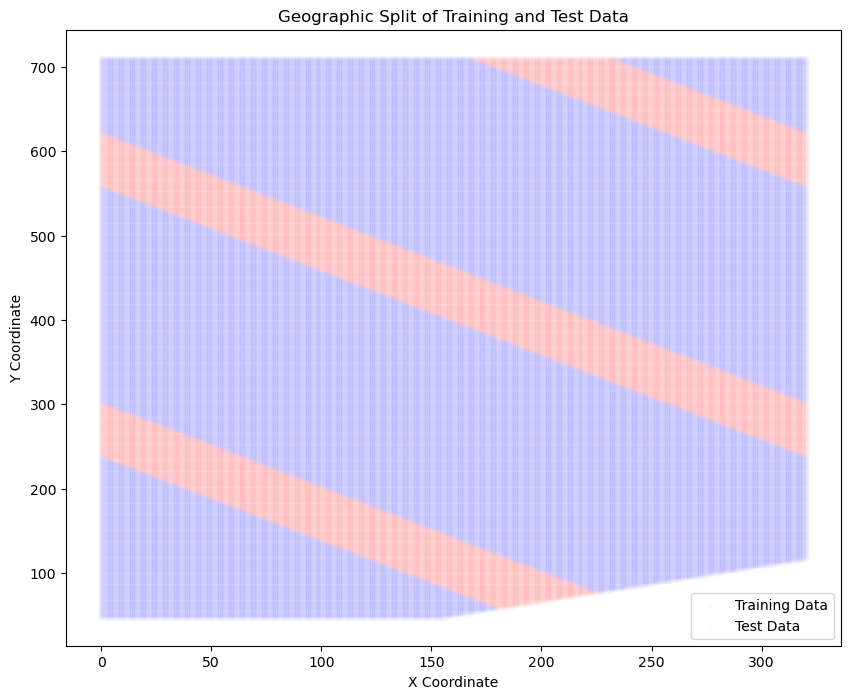

Training data size: 166279
Test data size: 41363
Actual test size ratio: 0.19920343668429316


In [31]:
workdf = raw_df[['x', 'y']].drop_duplicates()
# Define the column to use for swathes
x_column = 'x'
y_column = 'y'
swath_thickness = 0.2  # 15% of the x range

# Create diagonal swathes
df = create_diagonal_swathes(workdf, x_column, y_column, swath_thickness)

test_size=0.2
# Split the data based on the created swath column
train_data, test_data = split_by_swath(df, 'swath', test_size=test_size)

# Visualize the splits
visualize_splits(train_data, test_data, x_col=x_column, y_col=y_column)

# Verify the splits
print("Training data size:", len(train_data))
print("Test data size:", len(test_data))
print("Actual test size ratio:", len(test_data) / len(df))

In [49]:
result_df.groupby(['x', 'y']).count().sort_values('heading')

lidar  heading  pol_0_z_0  pol_0_z_1  pol_0_z_10  pol_0_z_11  \
x   y                                                                   
0   47       1        1          1          1           1           1   
194 519      1        1          1          1           1           1   
    520      1        1          1          1           1           1   
    521      1        1          1          1           1           1   
    522      1        1          1          1           1           1   
...        ...      ...        ...        ...         ...         ...   
175 491      2        2          2          2           2           2   
    492      2        2          2          2           2           2   
    493      2        2          2          2           2           2   
    487      2        2          2          2           2           2   
68  565      2        2          2          2           2           2   

         pol_0_z_12  pol_0_z_13  pol_0_z_14  pol_0_z_15  ...  pol_2_z_32  \
x   y                                                    ...               
0   47            1           1           1           1  ...           1   
194 519           1           1           1           1  ...           1   
    520           1           1           1           1  ...           1   
    521           1           1           1           1  ...           1   
    522           1           1           1           1  ...           1   
...             ...         ...         ...         ...  ...         ...   
175 491           2           2           2           2  ...           2   
    492           2           2           2           2  ...           2   
    493           2           2           2           2  ...           2   
    487           2           2           2           2  ...           2   
68  565           2           2           2           2  ...           2   

         pol_2_z_33  pol_2_z_34  pol_2_z_35  pol_2_z_4  pol_2_z_5  pol_2_z_6  \
x   y                                                                          
0   47            1           1           1          1          1          1   
194 519           1           1           1          1          1          1   
    520           1           1           1          1          1          1   
    521           1           1           1          1          1          1   
    522           1           1           1          1          1          1   
...             ...         ...         ...        ...        ...        ...   
175 491           2           2           2          2          2          2   
    492           2           2           2          2          2          2   
    493           2           2           2          2          2          2   
    487           2           2           2          2          2          2   
68  565           2           2           2          2          2          2   

         pol_2_z_7  pol_2_z_8  pol_2_z_9  
x   y                                     
0   47           1          1          1  
194 519          1          1          1  
    520          1          1          1  
    521          1          1          1  
    522          1          1          1  
...            ...        ...        ...  
175 491          2          2          2  
    492          2          2          2  
    493          2          2          2  
    487          2          2          2  
68  565          2          2          2  

[207642 rows x 110 columns]

In [35]:
train_data_swath = train_data.merge(result_df, on =['x', 'y'], how='inner')
test_data_swath = test_data.merge(result_df, on =['x', 'y'], how='inner')

if train_data_swath.merge(test_data_swath, on=['x', 'y'], how='inner').empty is True: 
    print('no overlap train and test ')
else:
    raise ValueError('Overlap in x and y between train and test ')

train_data_swath.to_csv(f'swathmldata_unionpolarimetry__train_data__swath_{swath_thickness}__testsize_{test_size}.csv')
test_data_swath.to_csv(f'swathmldata_unionpolarimetry__test_data__swath_{swath_thickness}__testsize_{test_size}.csv')

train_data_swath.shape , test_data_swath.shape

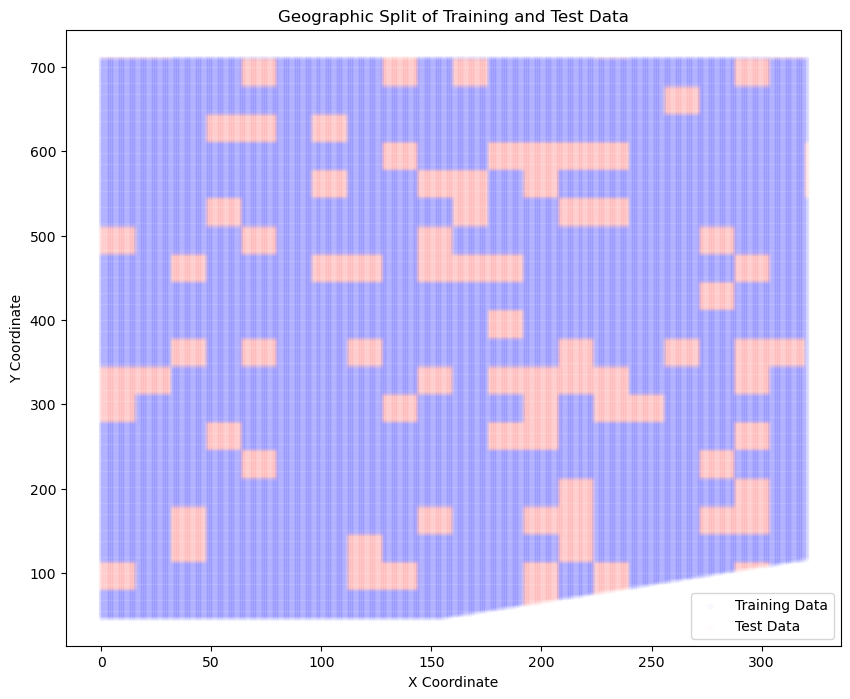

Training data size: 166874
Test data size: 40768
Actual test size ratio: 0.19633792777954365


In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def create_squares(data, x_col, y_col, square_size):
    x_min, x_max = data[x_col].min(), data[x_col].max()
    y_min, y_max = data[y_col].min(), data[y_col].max()
    x_range = x_max - x_min
    y_range = y_max - y_min
    
    # Calculate the square boundaries
    num_squares_x = int(np.ceil(1 / square_size))
    num_squares_y = int(np.ceil(y_range / (y_range * square_size)))  # Changed x_range to y_range
    
    data['x_square'] = ((data[x_col] - x_min) / (x_range * square_size)).astype(int)
    data['y_square'] = ((data[y_col] - y_min) / (y_range * square_size)).astype(int)  # Changed x_range to y_range
    
    return data
def split_by_squares(data, test_size=0.2, max_iterations=100):
    """
    Split the data into train and test sets based on squares, aiming for the specified test_size.
    
    Parameters:
    - data: DataFrame with 'x_square' and 'y_square' columns.
    - test_size: Proportion of the dataset to include in the test split.
    - max_iterations: Maximum number of iterations to attempt to achieve the desired split.
    
    Returns:
    - train_data: Training set.
    - test_data: Test set.
    """
    unique_squares = data[['x_square', 'y_square']].drop_duplicates()
    n_squares = len(unique_squares)
    
    best_split = None
    best_diff = float('inf')
    
    for _ in range(max_iterations):
        n_test_squares = max(1, int(n_squares * test_size))
        test_square_indices = np.random.choice(n_squares, size=n_test_squares, replace=False)
        test_squares = unique_squares.iloc[test_square_indices]
        
        test_mask = data.apply(lambda row: any((row['x_square'] == sq[0] and row['y_square'] == sq[1]) 
                                               for sq in test_squares.values), axis=1)
        
        test_data = data[test_mask]
        train_data = data[~test_mask]
        
        actual_test_size = len(test_data) / len(data)
        diff = abs(actual_test_size - test_size)
        
        if diff < best_diff:
            best_diff = diff
            best_split = (train_data, test_data)
        
        if diff < 0.01:  # If within 1% of desired test_size, break
            break
    
    return best_split

def visualize_splits(train_data, test_data, x_col='x', y_col='y'):
    """
    Visualize the training and test splits based on x and y coordinates.
    
    Parameters:
    - train_data: DataFrame for the training data.
    - test_data: DataFrame for the test data.
    - x_col: Column name for x coordinates.
    - y_col: Column name for y coordinates.
    """
    plt.figure(figsize=(10, 8))
    plt.scatter(train_data[x_col], train_data[y_col], c='blue', label='Training Data', alpha=0.02, s=10)
    plt.scatter(test_data[x_col], test_data[y_col], c='red', label='Test Data', alpha=0.01, s=10)
    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.legend()
    plt.title('Geographic Split of Training and Test Data')
    plt.show()

# Assume df is your DataFrame with 'x' and 'y' columns
workdf = result_df[['x', 'y']].drop_duplicates()

# Define the columns to use for squares
x_column = 'x'
y_column = 'y'
square_size = 0.05  

# Create squares
df_proc = create_squares(workdf, x_column, y_column, square_size)

test_size = 0.2
# Split the data based on the created squares
train_data, test_data = split_by_squares(df_proc, test_size=test_size)

# Visualize the splits
visualize_splits(train_data, test_data, x_col=x_column, y_col=y_column)

# Verify the splits
print("Training data size:", len(train_data))
print("Test data size:", len(test_data))
print("Actual test size ratio:", len(test_data) / len(df))

In [65]:
train_data_sq = train_data.merge(result_df, on =['x', 'y'], how='inner')
test_data_sq = test_data.merge(result_df, on =['x', 'y'], how='inner')


if train_data_sq.merge(test_data_sq, on=['x', 'y'], how='inner').empty is True: 
    print('no overlap train and test ')
else:
    raise ValueError('Overlap in x and y between train and test ')

train_data_sq.to_csv(f'squaremldata_unionpolarimetry__train_data__sq_{square_size}__testsize_{test_size}.csv')
test_data_sq.to_csv(f'squaremldata_unionpolarimetry__test_data__sq_{square_size}__testsize_{test_size}.csv')



no overlap train and test 


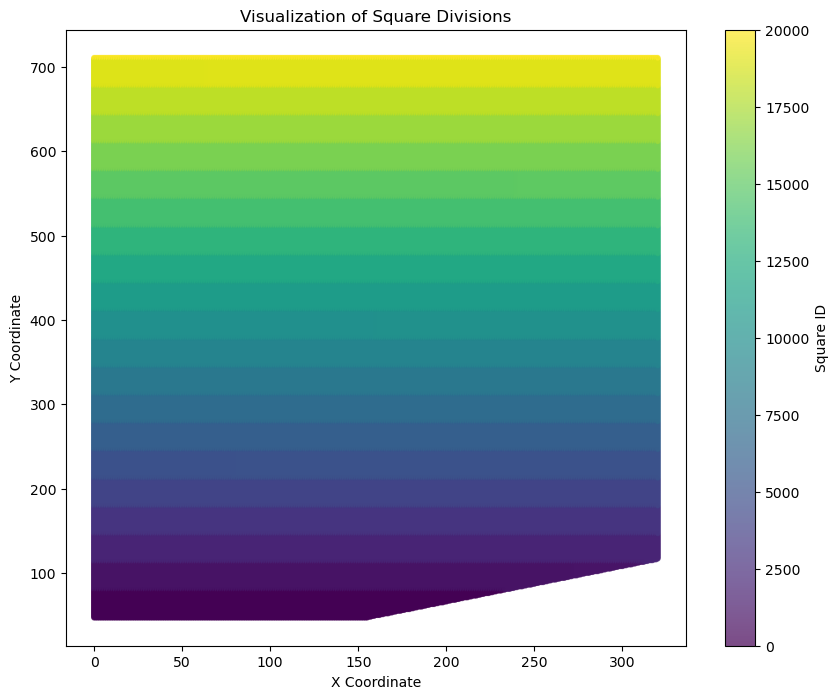

In [62]:
def visualize_squares(data, x_col='x', y_col='y'):
    plt.figure(figsize=(10, 8))
    plt.scatter(data[x_col], data[y_col], c=data['x_square'] + data['y_square'] * 1000, cmap='viridis', alpha=0.7, s=10)
    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.title('Visualization of Square Divisions')
    plt.colorbar(label='Square ID')
    plt.show()

# After creating squares
visualize_squares(df_proc, x_col=x_column, y_col=y_column)

In [7]:
train_data.to_csv(f'squaremldata__train_data__square_{square_size}__testsize_{test_size}.csv')
test_data.to_csv(f'squaremldata__test_data__square_{square_size}__testsize_{test_size}.csv')

KeyboardInterrupt: 